# E5_v2 — Latent landscape of phage lytic proteins

## Scientific question

**How is the phage-lytic protein space organized in learned PLM latent representations?**

E5_v2 analyzes the two frozen PLM spaces already available in the project:

- **ESM2-T6 8M**
- **ESM2-T30 150M**

T30 remains the production-model representation, but the EDA does not treat it as the only valid latent space.

## Hard rule

**No embeddings are generated in this notebook.** E5_v2 only reads the completed Parquet matrices already present in the project. Missing embeddings cause a hard stop.

## Biological questions

### Global lytic landscape

- `P_core`
- `N_easy`
- `N_hard`

A secondary binary summary retains `P_core` vs `N_mixed`.

### Functional lytic landscape

- Endolysin
- Depolymerase
- VAL

## Visualization

For each PLM, E5_v2 produces **PCA, UMAP and t-SNE**. UMAP and t-SNE are fitted **independently for the global and subtype questions**, so the subtype map is not distorted by points that are later hidden.

For t-SNE, each balanced visualization sample is first reduced to at most 50 dimensions with PCA. t-SNE is used strictly as a visualization.

## Quantitative analysis

All quantitative metrics are calculated in the **original embedding space with cosine geometry**, never on PCA, UMAP or t-SNE coordinates.

E5_v2 keeps only biologically useful metrics:

- cosine silhouette;
- within-group cosine dispersion;
- same-label kNN fraction;
- full neighborhood composition;
- local enrichment relative to the balanced expectation.

Balanced repeated subsampling is used for all metrics sensitive to class imbalance.

## Representation comparison

T6 and T30 are compared only at the level of the biological patterns they recover. E5_v2 does **not** test whether the two embedding spaces are geometrically equivalent, and therefore removes the pairwise-distance Spearman and cross-embedding kNN-Jaccard analyses from E5_v1.

All outputs are written to `EDA_results/E5_v2/`.

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pyarrow as pa
import pyarrow.parquet as pq

from sklearn.decomposition import IncrementalPCA, PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

try:
    import umap
except ImportError as exc:
    raise ImportError(
        "E5_v2 requires umap-learn for visualization. "
        "Install it in the active environment with: pip install umap-learn"
    ) from exc

from IPython.display import display

sns.set_theme(
    context="notebook",
    style="ticks",
    font_scale=1.0,
)

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 220)

RANDOM_SEED = 42

PCA_COMPONENTS = 20
PCA_BATCH_ROWS = 10_000

UMAP_N_NEIGHBORS = 30
UMAP_MIN_DIST = 0.20

TSNE_PRE_PCA_COMPONENTS = 50
TSNE_PERPLEXITY = 30
TSNE_MAX_ITER = 1_000

NEIGHBOR_K_VALUES = [10, 25, 50]

GLOBAL_METRIC_REPEATS = 5
GLOBAL_THREE_STATE_N_PER_GROUP = 1_000
GLOBAL_BINARY_N_PER_GROUP = 1_500

SUBTYPE_METRIC_REPEATS = 10
SUBTYPE_N_PER_GROUP = 200

GLOBAL_VIZ_N_PER_GROUP = 3_000
SUBTYPE_VIZ_N_PER_GROUP = 200

EMBEDDING_GENERATION_DISABLED = True

## 1. Paths and frozen representation registry

In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "EDA" else cwd

E0_PATH = (
    PROJECT_ROOT
    / "EDA_results"
    / "E0"
    / "phagelytic_eda_universe.csv"
)

EMBED_ROOT = (
    PROJECT_ROOT
    / "data"
    / "representations"
    / "sylphy_embeddings"
    / "models"
)

REPRESENTATIONS = {
    "esm2_t6": {
        "display_name": "ESM2-T6 8M",
        "model": "facebook/esm2_t6_8m_ur50d",
        "slug": "facebook_esm2_t6_8m_ur50d",
        "expected_dimensions": 320,
        "expected_rows": 434_768,
    },
    "esm2_t30": {
        "display_name": "ESM2-T30 150M",
        "model": "facebook/esm2_t30_150m_ur50d",
        "slug": "facebook_esm2_t30_150m_ur50d",
        "expected_dimensions": 640,
        "expected_rows": 434_768,
    },
}

for rep, cfg in REPRESENTATIONS.items():
    cfg["directory"] = EMBED_ROOT / cfg["slug"]
    cfg["parquet"] = (
        cfg["directory"]
        / "embeddings_last_mean_fp32.parquet"
    )
    cfg["metadata"] = (
        cfg["directory"]
        / "metadata.json"
    )

RESULT_DIR = PROJECT_ROOT / "EDA_results" / "E5_v2"
FIGURE_DIR = RESULT_DIR / "figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

AVAILABILITY_PATH = RESULT_DIR / "embedding_availability_audit.tsv"
COMMON_UNIVERSE_PATH = RESULT_DIR / "embedding_common_universe_summary.tsv"
SAMPLE_MANIFEST_PATH = RESULT_DIR / "embedding_sample_manifest.tsv"
PCA_VARIANCE_PATH = RESULT_DIR / "cross_embedding_pca_variance.tsv"
CROSS_BIOLOGICAL_PATH = RESULT_DIR / "cross_embedding_biological_summary.tsv"
CROSS_NEIGHBORHOOD_PATH = RESULT_DIR / "cross_embedding_neighborhood_summary.tsv"
METADATA_PATH = RESULT_DIR / "e5_v2_metadata.json"

if not E0_PATH.is_file():
    raise FileNotFoundError(
        f"Frozen E0 universe not found: {E0_PATH}"
    )

for rep, cfg in REPRESENTATIONS.items():
    if not cfg["parquet"].is_file():
        raise FileNotFoundError(
            f"Precomputed embedding parquet is absent for {rep}: "
            f"{cfg['parquet']}\n"
            "E5_v2 does not generate embeddings."
        )

    if not cfg["metadata"].is_file():
        raise FileNotFoundError(
            f"Embedding metadata is absent for {rep}: "
            f"{cfg['metadata']}"
        )

print(f"Project root  : {PROJECT_ROOT}")
print(f"Embedding root: {EMBED_ROOT}")
print(f"E5_v2 results : {RESULT_DIR}")

Project root  : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
Embedding root: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/data/representations/sylphy_embeddings/models
E5_v2 results : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2


## 2. Audit embedding metadata and parquet schemas

In [3]:
NON_EMBEDDING_COLUMNS = {
    "sequence",
    "seq",
    "sequence_uid",
    "id",
    "length",
    "index",
}


def numeric_projection_columns(parquet_path):
    pf = pq.ParquetFile(parquet_path)
    schema = pf.schema_arrow

    feature_columns = []

    for field in schema:
        if field.name.lower() in NON_EMBEDDING_COLUMNS:
            continue

        if (
            pa.types.is_floating(field.type)
            or pa.types.is_integer(field.type)
        ):
            feature_columns.append(
                field.name
            )

    def projection_index(name):
        match = re.fullmatch(
            r"p_(\d+)",
            str(name),
        )
        return (
            int(match.group(1))
            if match
            else 10**9
        )

    feature_columns = sorted(
        feature_columns,
        key=projection_index,
    )

    return pf, feature_columns


availability_rows = []

for rep, cfg in REPRESENTATIONS.items():
    metadata = json.loads(
        cfg["metadata"].read_text(
            encoding="utf-8"
        )
    )

    pf, feature_columns = numeric_projection_columns(
        cfg["parquet"]
    )

    cfg["metadata_payload"] = metadata
    cfg["feature_columns"] = feature_columns
    cfg["row_count"] = int(
        pf.metadata.num_rows
    )

    if "sequence_uid" not in pf.schema_arrow.names:
        raise RuntimeError(
            f"{rep}: sequence_uid is absent from embedding parquet."
        )

    if cfg["row_count"] != cfg["expected_rows"]:
        raise RuntimeError(
            f"{rep}: expected {cfg['expected_rows']:,} rows "
            f"but found {cfg['row_count']:,}."
        )

    if cfg["row_count"] != int(
        metadata["row_count"]
    ):
        raise RuntimeError(
            f"{rep}: parquet/metadata row-count mismatch."
        )

    if len(feature_columns) != int(
        metadata["embedding_dimensions"]
    ):
        raise RuntimeError(
            f"{rep}: detected {len(feature_columns)} embedding dimensions "
            f"but metadata reports {metadata['embedding_dimensions']}."
        )

    if len(feature_columns) != cfg[
        "expected_dimensions"
    ]:
        raise RuntimeError(
            f"{rep}: expected {cfg['expected_dimensions']} dimensions "
            f"but found {len(feature_columns)}."
        )

    if metadata.get("status") != "completed":
        raise RuntimeError(
            f"{rep}: metadata status is not completed."
        )

    availability_rows.append(
        {
            "representation": rep,
            "display_name": cfg["display_name"],
            "model": cfg["model"],
            "parquet_exists": True,
            "metadata_status": metadata.get(
                "status"
            ),
            "row_count": cfg["row_count"],
            "embedding_dimensions": len(
                feature_columns
            ),
            "embedding_dtype": metadata.get(
                "embedding_dtype"
            ),
            "precision": metadata.get(
                "precision"
            ),
            "pool": metadata.get("pool"),
            "layers": metadata.get("layers"),
            "layer_agg": metadata.get(
                "layer_agg"
            ),
            "max_length": metadata.get(
                "max_length"
            ),
            "canonical_amino_acids_only": metadata.get(
                "canonical_amino_acids_only"
            ),
            "frozen_sequence_count": metadata.get(
                "frozen_sequence_count"
            ),
            "eligible_sequence_count": metadata.get(
                "eligible_sequence_count"
            ),
            "filtered_sequence_count": metadata.get(
                "filtered_sequence_count"
            ),
        }
    )

embedding_availability = pd.DataFrame(
    availability_rows
)

embedding_availability.to_csv(
    AVAILABILITY_PATH,
    sep="\t",
    index=False,
)

display(embedding_availability)

,representation,display_name,model,parquet_exists,metadata_status,row_count,embedding_dimensions,embedding_dtype,precision,pool,layers,layer_agg,max_length,canonical_amino_acids_only,frozen_sequence_count,eligible_sequence_count,filtered_sequence_count
0,esm2_t6,ESM2-T6 8M,facebook/esm2_t6_8m_ur50d,True,completed,434768,320,float32,fp32,mean,last,mean,1024,True,442329,434768,7561
1,esm2_t30,ESM2-T30 150M,facebook/esm2_t30_150m_ur50d,True,completed,434768,640,float32,fp32,mean,last,mean,1024,True,442329,434768,7561


## 3. Recover the exact common embedding universe

In [4]:
uid_tables = {}

for rep, cfg in REPRESENTATIONS.items():
    uids = pd.read_parquet(
        cfg["parquet"],
        columns=["sequence_uid"],
    )

    uids["sequence_uid"] = (
        uids["sequence_uid"]
        .astype(str)
    )

    if uids["sequence_uid"].duplicated().any():
        raise RuntimeError(
            f"{rep}: duplicated sequence_uid values."
        )

    uid_tables[rep] = uids


rep_names = list(
    REPRESENTATIONS
)

common_uids = set(
    uid_tables[
        rep_names[0]
    ]["sequence_uid"]
)

for rep in rep_names[1:]:
    common_uids &= set(
        uid_tables[
            rep
        ]["sequence_uid"]
    )

union_uids = set()

for rep in rep_names:
    union_uids |= set(
        uid_tables[
            rep
        ]["sequence_uid"]
    )

exact_uid_contract = all(
    set(
        uid_tables[
            rep
        ]["sequence_uid"]
    )
    == common_uids
    for rep in rep_names
)

if not exact_uid_contract:
    raise RuntimeError(
        "T6 and T30 do not have the same sequence_uid universe. "
        "E5 currently requires an exact paired universe."
    )


e0 = pd.read_csv(
    E0_PATH,
    usecols=[
        "sequence_uid",
        "sequence_state",
        "clean_subtype",
    ],
    dtype={
        "sequence_uid": str,
        "sequence_state": str,
        "clean_subtype": str,
    },
    low_memory=False,
)

assert len(e0) == 442_329
assert e0["sequence_uid"].is_unique

e0["binary_label"] = pd.Series(
    pd.NA,
    index=e0.index,
    dtype="string",
)

e0.loc[
    e0["sequence_state"].eq("P_core"),
    "binary_label",
] = "P_core"

e0.loc[
    e0["sequence_state"].isin(
        ["N_easy", "N_hard"]
    ),
    "binary_label",
] = "N_mixed"


CLEAN_SUBTYPES = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

e0["subtype_label"] = pd.Series(
    pd.NA,
    index=e0.index,
    dtype="string",
)

clean_mask = e0[
    "clean_subtype"
].isin(
    CLEAN_SUBTYPES
)

e0.loc[
    clean_mask,
    "subtype_label",
] = (
    e0.loc[
        clean_mask,
        "clean_subtype",
    ]
    .astype("string")
)


common_labels = e0.loc[
    e0["sequence_uid"].isin(
        common_uids
    )
].copy()

if len(common_labels) != len(
    common_uids
):
    raise RuntimeError(
        "Common embedding universe could not be mapped one-to-one to E0."
    )

common_summary = pd.DataFrame(
    [
        {
            "scope": "E0_frozen",
            "n_sequences": len(e0),
        },
        {
            "scope": "embedding_common_universe",
            "n_sequences": len(
                common_labels
            ),
        },
        {
            "scope": "E0_without_precomputed_embeddings",
            "n_sequences": (
                len(e0)
                - len(common_labels)
            ),
        },
    ]
)

common_summary.to_csv(
    COMMON_UNIVERSE_PATH,
    sep="\t",
    index=False,
)

print(
    f"E0 frozen universe       : {len(e0):,}"
)
print(
    f"Common T6/T30 universe   : {len(common_labels):,}"
)
print(
    f"Not represented by PLMs  : "
    f"{len(e0) - len(common_labels):,}"
)

print()
print("Common-universe primary states")
display(
    common_labels[
        "sequence_state"
    ]
    .value_counts()
    .rename("n")
    .to_frame()
)

print()
print("Common-universe clean subtypes")
display(
    common_labels[
        "subtype_label"
    ]
    .value_counts(
        dropna=False
    )
    .rename("n")
    .to_frame()
)

E0 frozen universe       : 442,329
Common T6/T30 universe   : 434,768
Not represented by PLMs  : 7,561

Common-universe primary states


,n
sequence_state,
U_explicit,227256
U_other_unresolved,128181
N_easy,53867
P_core,11259
challenge_ambiguous_structural,9613
N_hard,4322
challenge_lytic_related,270



Common-universe clean subtypes


,n
subtype_label,
<NA>,424524
endolysin,9371
depolymerase,635
virion_associated_lytic_enzyme,238


## 4. Freeze paired balanced samples shared by T6 and T30

In [5]:
def balanced_sample_uids(
    data,
    group_col,
    groups,
    n_per_group,
    seed,
):
    rng = np.random.default_rng(seed)
    selected = []

    for group in groups:
        candidates = (
            data.loc[
                data[group_col].eq(group),
                "sequence_uid",
            ]
            .astype(str)
            .to_numpy()
        )

        if len(candidates) < n_per_group:
            raise RuntimeError(
                f"Not enough sequences for {group_col}={group}: "
                f"requested {n_per_group}, available {len(candidates)}."
            )

        sampled = rng.choice(
            candidates,
            size=n_per_group,
            replace=False,
        )
        selected.extend(sampled.tolist())

    return selected


GLOBAL_THREE_GROUPS = [
    "P_core",
    "N_easy",
    "N_hard",
]

GLOBAL_BINARY_GROUPS = [
    "P_core",
    "N_mixed",
]

SUBTYPE_GROUPS = CLEAN_SUBTYPES


global_viz_uids = balanced_sample_uids(
    common_labels,
    group_col="sequence_state",
    groups=GLOBAL_THREE_GROUPS,
    n_per_group=GLOBAL_VIZ_N_PER_GROUP,
    seed=RANDOM_SEED,
)

subtype_viz_uids = balanced_sample_uids(
    common_labels.loc[
        common_labels["subtype_label"].notna()
    ],
    group_col="subtype_label",
    groups=SUBTYPE_GROUPS,
    n_per_group=SUBTYPE_VIZ_N_PER_GROUP,
    seed=RANDOM_SEED + 1,
)


SCOPE_CONFIG = {
    "global_three_state": {
        "group_col": "sequence_state",
        "groups": GLOBAL_THREE_GROUPS,
        "n_per_group": GLOBAL_THREE_STATE_N_PER_GROUP,
        "repeats": GLOBAL_METRIC_REPEATS,
    },
    "global_binary": {
        "group_col": "binary_label",
        "groups": GLOBAL_BINARY_GROUPS,
        "n_per_group": GLOBAL_BINARY_N_PER_GROUP,
        "repeats": GLOBAL_METRIC_REPEATS,
    },
    "clean_subtypes": {
        "group_col": "subtype_label",
        "groups": SUBTYPE_GROUPS,
        "n_per_group": SUBTYPE_N_PER_GROUP,
        "repeats": SUBTYPE_METRIC_REPEATS,
    },
}

METRIC_SAMPLE_PLANS = {}

for scope_name, config in SCOPE_CONFIG.items():
    scope_data = common_labels.loc[
        common_labels[
            config["group_col"]
        ].isin(config["groups"])
    ]

    for repeat in range(config["repeats"]):
        METRIC_SAMPLE_PLANS[(scope_name, repeat)] = balanced_sample_uids(
            scope_data,
            group_col=config["group_col"],
            groups=config["groups"],
            n_per_group=config["n_per_group"],
            seed=(
                RANDOM_SEED
                + repeat * 101
                + len(scope_name) * 10_000
            ),
        )

required_sample_uids = set(global_viz_uids) | set(subtype_viz_uids)

for sample_uids in METRIC_SAMPLE_PLANS.values():
    required_sample_uids |= set(sample_uids)

sample_manifest = common_labels.loc[
    common_labels["sequence_uid"].isin(required_sample_uids),
    [
        "sequence_uid",
        "sequence_state",
        "binary_label",
        "clean_subtype",
        "subtype_label",
    ],
].copy()

sample_manifest["in_global_viz_sample"] = sample_manifest[
    "sequence_uid"
].isin(global_viz_uids)

sample_manifest["in_subtype_viz_sample"] = sample_manifest[
    "sequence_uid"
].isin(subtype_viz_uids)

sample_manifest.to_csv(
    SAMPLE_MANIFEST_PATH,
    sep="\t",
    index=False,
)

print(
    f"Global visualization sample : {len(global_viz_uids):,}"
)
print(
    f"Subtype visualization sample: {len(subtype_viz_uids):,}"
)
print(
    f"Union required for E5_v2   : {len(required_sample_uids):,}"
)

Global visualization sample : 9,000
Subtype visualization sample: 600
Union required for E5_v2   : 26,664


## 5. Streaming helpers — consume embeddings without regenerating them

In [6]:
def batch_to_matrix(
    batch,
    feature_columns,
):
    frame = batch.to_pandas()

    matrix = frame[
        feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    if not np.isfinite(
        matrix
    ).all():
        raise RuntimeError(
            "Non-finite values detected in frozen embedding matrix."
        )

    return frame, matrix


def fit_incremental_pca_on_parquet(
    parquet_path,
    feature_columns,
    n_components,
):
    model = IncrementalPCA(
        n_components=n_components,
        batch_size=PCA_BATCH_ROWS,
    )

    pf = pq.ParquetFile(
        parquet_path
    )

    for batch in pf.iter_batches(
        batch_size=PCA_BATCH_ROWS,
        columns=feature_columns,
    ):
        _, x = batch_to_matrix(
            batch,
            feature_columns,
        )

        model.partial_fit(x)

    return model


def extract_selected_embeddings(
    parquet_path,
    feature_columns,
    selected_uids,
):
    selected_uids = set(
        str(uid)
        for uid in selected_uids
    )

    pf = pq.ParquetFile(
        parquet_path
    )

    pieces = []

    for batch in pf.iter_batches(
        batch_size=PCA_BATCH_ROWS,
        columns=[
            "sequence_uid"
        ] + feature_columns,
    ):
        frame = batch.to_pandas()

        frame[
            "sequence_uid"
        ] = frame[
            "sequence_uid"
        ].astype(str)

        mask = frame[
            "sequence_uid"
        ].isin(
            selected_uids
        )

        if mask.any():
            pieces.append(
                frame.loc[
                    mask
                ].copy()
            )

    if not pieces:
        raise RuntimeError(
            "No selected embeddings were extracted."
        )

    selected = pd.concat(
        pieces,
        ignore_index=True,
    )

    if selected[
        "sequence_uid"
    ].duplicated().any():
        raise RuntimeError(
            "Selected embedding extraction produced duplicate sequence_uid."
        )

    observed = set(
        selected[
            "sequence_uid"
        ]
    )

    missing = (
        selected_uids
        - observed
    )

    if missing:
        raise RuntimeError(
            f"Selected embedding extraction missed {len(missing)} sequence_uid values."
        )

    matrix = selected[
        feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    if not np.isfinite(
        matrix
    ).all():
        raise RuntimeError(
            "Selected embedding matrix contains NaN/Inf."
        )

    return selected


def l2_normalize_rows(x):
    norms = np.linalg.norm(
        x,
        axis=1,
        keepdims=True,
    )

    if np.any(norms == 0):
        raise RuntimeError(
            "Zero-norm embedding vector detected."
        )

    return x / norms


def cosine_distance_to_centroid(
    x_normalized,
    centroid_normalized,
):
    similarities = (
        x_normalized
        @ centroid_normalized
    )

    return (
        1.0
        - similarities
    )

def sample_by_uid_order(
    frame,
    uid_order,
):
    indexed = frame.set_index(
        "sequence_uid",
        drop=False,
    )

    return (
        indexed.loc[
            [
                str(uid)
                for uid in uid_order
            ]
        ]
        .reset_index(
            drop=True
        )
    )


## 6. Fit PCA on the complete common universe and extract the paired working samples

In [7]:
REP_DATA = {}
pca_variance_rows = []

for rep, cfg in REPRESENTATIONS.items():
    print()
    print("=" * 72)
    print(
        f"{cfg['display_name']} "
        f"({len(cfg['feature_columns'])}D)"
    )
    print("=" * 72)

    n_components = min(
        PCA_COMPONENTS,
        len(
            cfg[
                "feature_columns"
            ]
        ),
    )

    pca_model = fit_incremental_pca_on_parquet(
        cfg["parquet"],
        cfg["feature_columns"],
        n_components=n_components,
    )

    selected = extract_selected_embeddings(
        cfg["parquet"],
        cfg["feature_columns"],
        required_sample_uids,
    )

    selected = sample_manifest.merge(
        selected,
        on="sequence_uid",
        how="left",
        validate="one_to_one",
    )

    if selected[
        cfg[
            "feature_columns"
        ]
    ].isna().any().any():
        raise RuntimeError(
            f"{rep}: missing embeddings after sample join."
        )

    REP_DATA[rep] = {
        "pca_model": pca_model,
        "sample": selected,
    }

    cumulative = np.cumsum(
        pca_model.explained_variance_ratio_
    )

    for component_idx, ratio in enumerate(
        pca_model.explained_variance_ratio_,
        start=1,
    ):
        pca_variance_rows.append(
            {
                "representation": rep,
                "display_name": cfg["display_name"],
                "component": component_idx,
                "explained_variance_ratio": float(
                    ratio
                ),
                "cumulative_explained_variance_ratio": float(
                    cumulative[
                        component_idx - 1
                    ]
                ),
            }
        )


pca_variance = pd.DataFrame(
    pca_variance_rows
)

pca_variance.to_csv(
    PCA_VARIANCE_PATH,
    sep="\t",
    index=False,
)

display(
    pca_variance.loc[
        pca_variance[
            "component"
        ].isin(
            [1, 2, 5, 10, 20]
        )
    ]
)


ESM2-T6 8M (320D)

ESM2-T30 150M (640D)


,representation,display_name,component,explained_variance_ratio,cumulative_explained_variance_ratio
0,esm2_t6,ESM2-T6 8M,1,0.132739,0.132739
1,esm2_t6,ESM2-T6 8M,2,0.111998,0.244736
4,esm2_t6,ESM2-T6 8M,5,0.058510,0.472303
9,esm2_t6,ESM2-T6 8M,10,0.023769,0.633659
19,esm2_t6,ESM2-T6 8M,20,0.009140,0.769906
20,esm2_t30,ESM2-T30 150M,1,0.206255,0.206255
21,esm2_t30,ESM2-T30 150M,2,0.096993,0.303247
24,esm2_t30,ESM2-T30 150M,5,0.049135,0.481192
29,esm2_t30,ESM2-T30 150M,10,0.018754,0.610908
39,esm2_t30,ESM2-T30 150M,20,0.008681,0.739245


## 7. PCA coordinates

In [8]:
for rep, cfg in REPRESENTATIONS.items():
    sample = REP_DATA[rep]["sample"]

    x = sample[
        cfg["feature_columns"]
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    pca_coords = REP_DATA[rep]["pca_model"].transform(x)

    pca_table = sample[
        [
            "sequence_uid",
            "sequence_state",
            "binary_label",
            "clean_subtype",
            "subtype_label",
            "in_global_viz_sample",
            "in_subtype_viz_sample",
        ]
    ].copy()

    for idx in range(min(5, pca_coords.shape[1])):
        pca_table[f"PC{idx + 1}"] = pca_coords[:, idx]

    pca_path = RESULT_DIR / f"embedding_{rep}_pca.tsv"
    pca_table.to_csv(
        pca_path,
        sep="\t",
        index=False,
    )

    REP_DATA[rep]["pca_coordinates"] = pca_table
    print(f"Saved: {pca_path}")

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t6_pca.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t30_pca.tsv


## 8. Independent UMAP landscapes

In [9]:
def fit_umap_scope(
    sample,
    feature_columns,
    uid_order,
    label_columns,
    seed,
):
    scope_sample = sample_by_uid_order(
        sample,
        uid_order,
    )

    x = scope_sample[
        feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    model = umap.UMAP(
        n_components=2,
        n_neighbors=UMAP_N_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        metric="cosine",
        random_state=seed,
        transform_seed=seed,
        low_memory=True,
    )

    coords = model.fit_transform(x)

    out = scope_sample[
        ["sequence_uid"] + label_columns
    ].copy()
    out["UMAP1"] = coords[:, 0]
    out["UMAP2"] = coords[:, 1]

    return out


for rep, cfg in REPRESENTATIONS.items():
    sample = REP_DATA[rep]["sample"]

    global_umap = fit_umap_scope(
        sample,
        cfg["feature_columns"],
        global_viz_uids,
        ["sequence_state", "binary_label"],
        RANDOM_SEED,
    )

    subtype_umap = fit_umap_scope(
        sample,
        cfg["feature_columns"],
        subtype_viz_uids,
        ["clean_subtype", "subtype_label"],
        RANDOM_SEED + 1,
    )

    global_path = RESULT_DIR / f"embedding_{rep}_umap_global.tsv"
    subtype_path = RESULT_DIR / f"embedding_{rep}_umap_subtypes.tsv"

    global_umap.to_csv(global_path, sep="\t", index=False)
    subtype_umap.to_csv(subtype_path, sep="\t", index=False)

    REP_DATA[rep]["umap_global"] = global_umap
    REP_DATA[rep]["umap_subtypes"] = subtype_umap

    print(f"Saved: {global_path}")
    print(f"Saved: {subtype_path}")

/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t6_umap_global.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t6_umap_subtypes.tsv


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t30_umap_global.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t30_umap_subtypes.tsv


## 9. Independent t-SNE landscapes

In [10]:
def fit_tsne_scope(
    sample,
    feature_columns,
    uid_order,
    label_columns,
    seed,
):
    scope_sample = sample_by_uid_order(
        sample,
        uid_order,
    )

    x = scope_sample[
        feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    n_pre_components = min(
        TSNE_PRE_PCA_COMPONENTS,
        x.shape[1],
        x.shape[0] - 1,
    )

    pre_pca = PCA(
        n_components=n_pre_components,
        svd_solver="randomized",
        random_state=seed,
    )

    x_reduced = pre_pca.fit_transform(x)

    tsne = TSNE(
        n_components=2,
        perplexity=TSNE_PERPLEXITY,
        learning_rate="auto",
        init="pca",
        max_iter=TSNE_MAX_ITER,
        metric="euclidean",
        random_state=seed,
        n_jobs=-1,
    )

    coords = tsne.fit_transform(x_reduced)

    out = scope_sample[
        ["sequence_uid"] + label_columns
    ].copy()
    out["TSNE1"] = coords[:, 0]
    out["TSNE2"] = coords[:, 1]
    out["pre_pca_components"] = n_pre_components

    return out


for rep, cfg in REPRESENTATIONS.items():
    sample = REP_DATA[rep]["sample"]

    global_tsne = fit_tsne_scope(
        sample,
        cfg["feature_columns"],
        global_viz_uids,
        ["sequence_state", "binary_label"],
        RANDOM_SEED + 100,
    )

    subtype_tsne = fit_tsne_scope(
        sample,
        cfg["feature_columns"],
        subtype_viz_uids,
        ["clean_subtype", "subtype_label"],
        RANDOM_SEED + 101,
    )

    global_path = RESULT_DIR / f"embedding_{rep}_tsne_global.tsv"
    subtype_path = RESULT_DIR / f"embedding_{rep}_tsne_subtypes.tsv"

    global_tsne.to_csv(global_path, sep="\t", index=False)
    subtype_tsne.to_csv(subtype_path, sep="\t", index=False)

    REP_DATA[rep]["tsne_global"] = global_tsne
    REP_DATA[rep]["tsne_subtypes"] = subtype_tsne

    print(f"Saved: {global_path}")
    print(f"Saved: {subtype_path}")

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t6_tsne_global.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t6_tsne_subtypes.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t30_tsne_global.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t30_tsne_subtypes.tsv


## 10. Quantitative latent organization in the original embedding space

In [11]:
def latent_biological_metrics(
    sample_df,
    feature_columns,
    group_col,
    groups,
    k_values,
    silhouette_seed,
):
    labels = (
        sample_df[group_col]
        .astype(str)
        .to_numpy()
    )

    x = sample_df[
        feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    x_normalized = l2_normalize_rows(x)

    silhouette = float(
        silhouette_score(
            x,
            labels,
            metric="cosine",
            sample_size=min(1_500, len(x)),
            random_state=silhouette_seed,
        )
    )

    geometry_rows = [
        {
            "metric": "silhouette_cosine",
            "group": "",
            "k": np.nan,
            "value": silhouette,
        }
    ]

    for group in groups:
        group_matrix = x_normalized[
            labels == group
        ]

        centroid = group_matrix.mean(axis=0)
        centroid_norm = np.linalg.norm(centroid)

        if centroid_norm == 0:
            raise RuntimeError(
                f"Zero-norm centroid for {group}."
            )

        centroid = centroid / centroid_norm
        cosine_distances = 1.0 - (group_matrix @ centroid)

        geometry_rows.append(
            {
                "metric": "within_group_cosine_dispersion",
                "group": group,
                "k": np.nan,
                "value": float(np.mean(cosine_distances)),
            }
        )

    neighborhood_rows = []

    for k in k_values:
        if k >= len(x):
            raise RuntimeError(
                f"k={k} invalid for n={len(x)}."
            )

        nn = NearestNeighbors(
            n_neighbors=k + 1,
            metric="cosine",
            algorithm="brute",
            n_jobs=-1,
        )
        nn.fit(x)

        neighbor_indices = nn.kneighbors(
            x,
            return_distance=False,
        )[:, 1:]
        neighbor_labels = labels[neighbor_indices]

        baseline_fraction = 1.0 / len(groups)
        same_label_by_group = []

        for focal_group in groups:
            focal_neighbors = neighbor_labels[
                labels == focal_group
            ]

            same_fraction = float(
                np.mean(focal_neighbors == focal_group)
            )
            same_label_by_group.append(same_fraction)

            geometry_rows.append(
                {
                    "metric": "same_label_knn_fraction",
                    "group": focal_group,
                    "k": k,
                    "value": same_fraction,
                }
            )

            for neighbor_group in groups:
                fraction = float(
                    np.mean(focal_neighbors == neighbor_group)
                )

                neighborhood_rows.append(
                    {
                        "k": k,
                        "focal_group": focal_group,
                        "neighbor_group": neighbor_group,
                        "neighbor_fraction": fraction,
                        "balanced_expected_fraction": baseline_fraction,
                        "local_enrichment": fraction / baseline_fraction,
                    }
                )

        geometry_rows.append(
            {
                "metric": "macro_same_label_knn_fraction",
                "group": "",
                "k": k,
                "value": float(np.mean(same_label_by_group)),
            }
        )

    return geometry_rows, neighborhood_rows

In [12]:
for rep, cfg in REPRESENTATIONS.items():
    print()
    print(f"Biological latent metrics: {cfg['display_name']}")

    sample_frame = REP_DATA[rep]["sample"]
    geometry_rows = []
    neighborhood_rows = []

    for scope_name, config in SCOPE_CONFIG.items():
        for repeat in range(config["repeats"]):
            uid_order = METRIC_SAMPLE_PLANS[(scope_name, repeat)]
            scope_sample = sample_by_uid_order(
                sample_frame,
                uid_order,
            )

            g_rows, n_rows = latent_biological_metrics(
                scope_sample,
                cfg["feature_columns"],
                group_col=config["group_col"],
                groups=config["groups"],
                k_values=NEIGHBOR_K_VALUES,
                silhouette_seed=RANDOM_SEED + repeat,
            )

            for row in g_rows:
                row.update(
                    {
                        "representation": rep,
                        "scope": scope_name,
                        "repeat": repeat,
                    }
                )

            for row in n_rows:
                row.update(
                    {
                        "representation": rep,
                        "scope": scope_name,
                        "repeat": repeat,
                    }
                )

            geometry_rows.extend(g_rows)
            neighborhood_rows.extend(n_rows)

    geometry_repeats = pd.DataFrame(geometry_rows)
    neighborhood_repeats = pd.DataFrame(neighborhood_rows)

    geometry_summary = (
        geometry_repeats
        .groupby(
            [
                "representation",
                "scope",
                "metric",
                "group",
                "k",
            ],
            dropna=False,
        )["value"]
        .agg(
            mean="mean",
            std="std",
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
            n_repeats="size",
        )
        .reset_index()
    )

    neighborhood_summary = (
        neighborhood_repeats
        .groupby(
            [
                "representation",
                "scope",
                "k",
                "focal_group",
                "neighbor_group",
                "balanced_expected_fraction",
            ],
            dropna=False,
        )
        .agg(
            mean_neighbor_fraction=("neighbor_fraction", "mean"),
            std_neighbor_fraction=("neighbor_fraction", "std"),
            median_neighbor_fraction=("neighbor_fraction", "median"),
            mean_local_enrichment=("local_enrichment", "mean"),
            std_local_enrichment=("local_enrichment", "std"),
            n_repeats=("local_enrichment", "size"),
        )
        .reset_index()
    )

    geometry_path = RESULT_DIR / f"embedding_{rep}_geometry.tsv"
    neighbor_path = RESULT_DIR / f"embedding_{rep}_neighbors.tsv"
    geometry_repeats_path = RESULT_DIR / f"embedding_{rep}_geometry_repeats.tsv"
    neighbor_repeats_path = RESULT_DIR / f"embedding_{rep}_neighbor_repeats.tsv"

    geometry_summary.to_csv(geometry_path, sep="\t", index=False)
    neighborhood_summary.to_csv(neighbor_path, sep="\t", index=False)
    geometry_repeats.to_csv(geometry_repeats_path, sep="\t", index=False)
    neighborhood_repeats.to_csv(neighbor_repeats_path, sep="\t", index=False)

    REP_DATA[rep]["geometry_summary"] = geometry_summary
    REP_DATA[rep]["neighbor_summary"] = neighborhood_summary

    print(f"Saved: {geometry_path}")
    print(f"Saved: {neighbor_path}")


Biological latent metrics: ESM2-T6 8M
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t6_geometry.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t6_neighbors.tsv

Biological latent metrics: ESM2-T30 150M
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t30_geometry.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/embedding_esm2_t30_neighbors.tsv


## 11. Cross-representation biological summaries

In [13]:
cross_biological = pd.concat(
    [
        REP_DATA[rep]["geometry_summary"]
        for rep in REPRESENTATIONS
    ],
    ignore_index=True,
)

cross_biological["display_name"] = cross_biological[
    "representation"
].map(
    {
        rep: cfg["display_name"]
        for rep, cfg in REPRESENTATIONS.items()
    }
)

cross_biological.to_csv(
    CROSS_BIOLOGICAL_PATH,
    sep="\t",
    index=False,
)

cross_neighborhood = pd.concat(
    [
        REP_DATA[rep]["neighbor_summary"]
        for rep in REPRESENTATIONS
    ],
    ignore_index=True,
)

cross_neighborhood["display_name"] = cross_neighborhood[
    "representation"
].map(
    {
        rep: cfg["display_name"]
        for rep, cfg in REPRESENTATIONS.items()
    }
)

cross_neighborhood.to_csv(
    CROSS_NEIGHBORHOOD_PATH,
    sep="\t",
    index=False,
)

print("Primary biological summary")
display(
    cross_biological.loc[
        cross_biological["metric"].isin(
            [
                "silhouette_cosine",
                "macro_same_label_knn_fraction",
                "within_group_cosine_dispersion",
            ]
        )
    ].sort_values(
        [
            "scope",
            "metric",
            "group",
            "k",
            "representation",
        ]
    )
)

Primary biological summary


,representation,scope,metric,group,k,mean,std,median,q25,q75,n_repeats,display_name
44,esm2_t30,clean_subtypes,macro_same_label_knn_fraction,,10.0,0.919267,0.006548,0.919167,0.917542,0.924167,10,ESM2-T30 150M
0,esm2_t6,clean_subtypes,macro_same_label_knn_fraction,,10.0,0.886850,0.005182,0.887667,0.881833,0.890542,10,ESM2-T6 8M
45,esm2_t30,clean_subtypes,macro_same_label_knn_fraction,,25.0,0.887187,0.006707,0.889133,0.885100,0.890033,10,ESM2-T30 150M
1,esm2_t6,clean_subtypes,macro_same_label_knn_fraction,,25.0,0.845267,0.004659,0.845467,0.841700,0.848833,10,ESM2-T6 8M
46,esm2_t30,clean_subtypes,macro_same_label_knn_fraction,,50.0,0.867973,0.006723,0.869550,0.867217,0.871433,10,ESM2-T30 150M
2,esm2_t6,clean_subtypes,macro_same_label_knn_fraction,,50.0,0.814187,0.003819,0.814933,0.811533,0.817442,10,ESM2-T6 8M
56,esm2_t30,clean_subtypes,silhouette_cosine,,NaN,0.219986,0.006866,0.220088,0.215286,0.225550,10,ESM2-T30 150M
12,esm2_t6,clean_subtypes,silhouette_cosine,,NaN,0.219210,0.010382,0.220529,0.210073,0.224122,10,ESM2-T6 8M
57,esm2_t30,clean_subtypes,within_group_cosine_dispersion,depolymerase,NaN,0.012994,0.000921,0.012859,0.012225,0.013605,10,ESM2-T30 150M
13,esm2_t6,clean_subtypes,within_group_cosine_dispersion,depolymerase,NaN,0.025438,0.001478,0.025557,0.024126,0.026315,10,ESM2-T6 8M


## 12. Figures

In [14]:
def save_figure(
    fig,
    stem,
):
    png = (
        FIGURE_DIR
        / f"{stem}.png"
    )

    pdf = (
        FIGURE_DIR
        / f"{stem}.pdf"
    )

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf,
        bbox_inches="tight",
    )

    print(f"Saved: {png}")
    print(f"Saved: {pdf}")


GLOBAL_HUE_ORDER = [
    "P_core",
    "N_easy",
    "N_hard",
]

SUBTYPE_HUE_ORDER = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_PCA_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_PCA_global.pdf


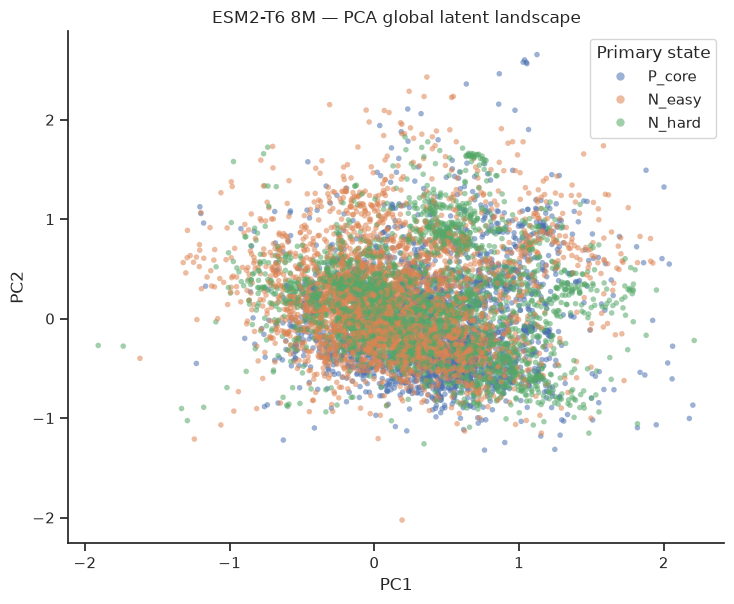

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_PCA_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_PCA_subtypes.pdf


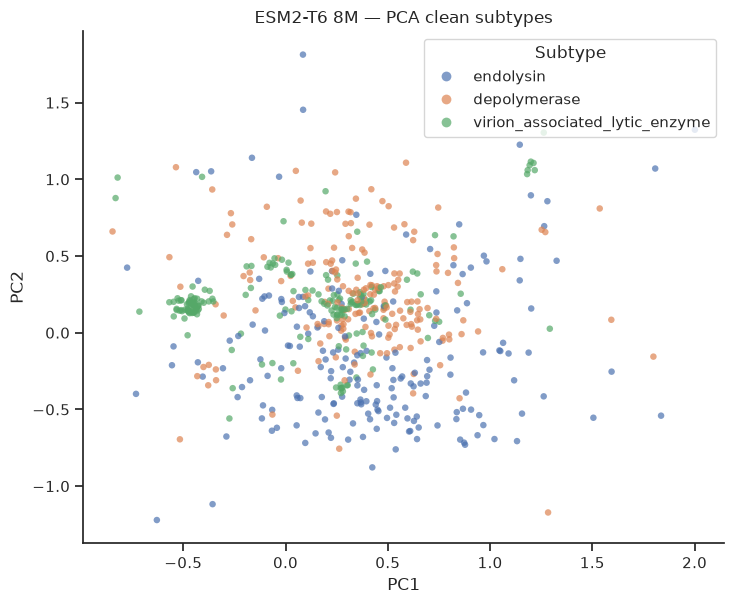

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_UMAP_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_UMAP_global.pdf


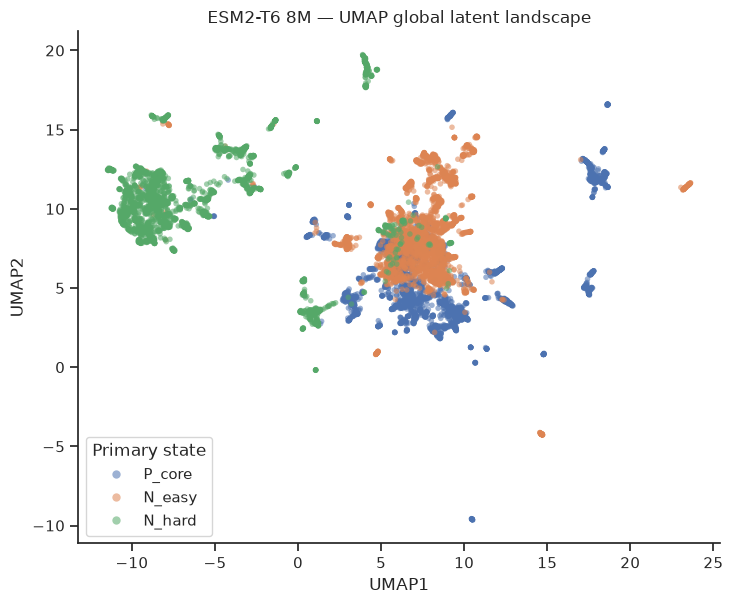

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_UMAP_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_UMAP_subtypes.pdf


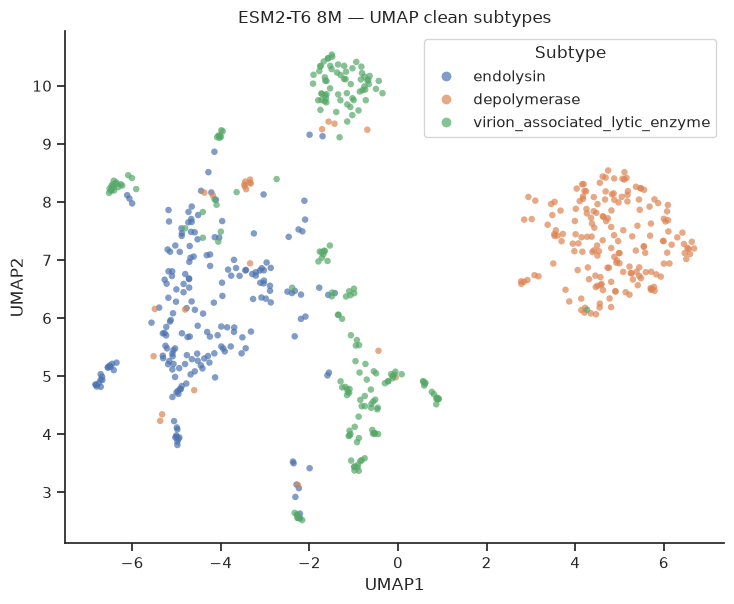

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_TSNE_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_TSNE_global.pdf


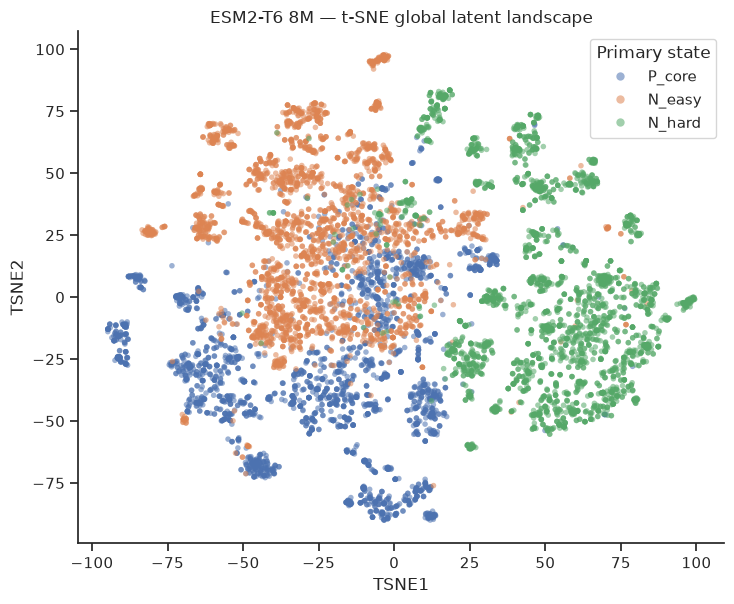

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_TSNE_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t6_TSNE_subtypes.pdf


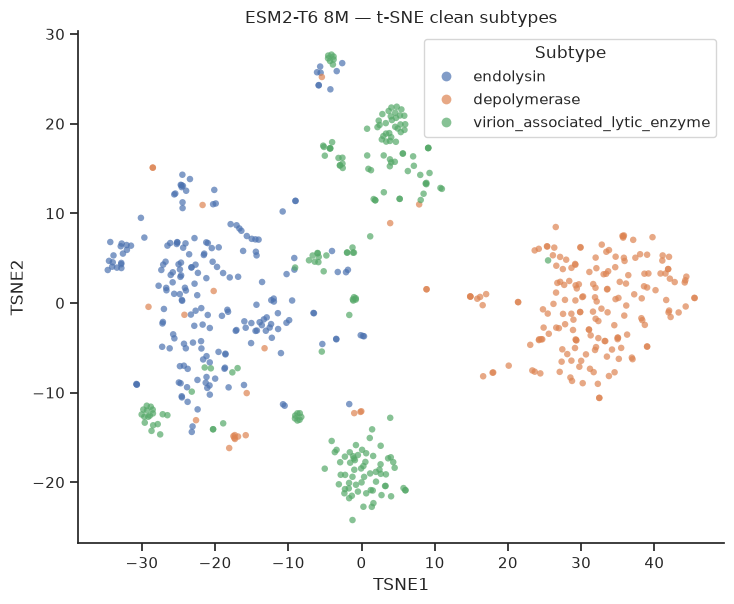

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_PCA_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_PCA_global.pdf


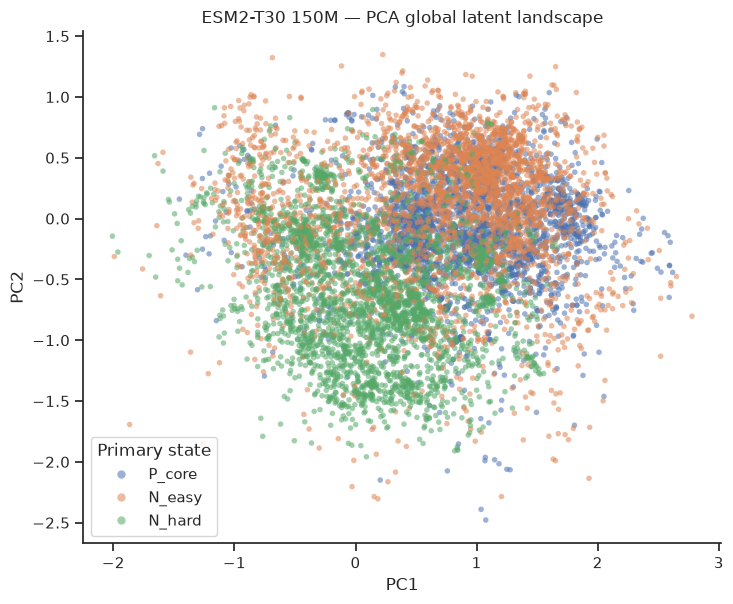

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_PCA_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_PCA_subtypes.pdf


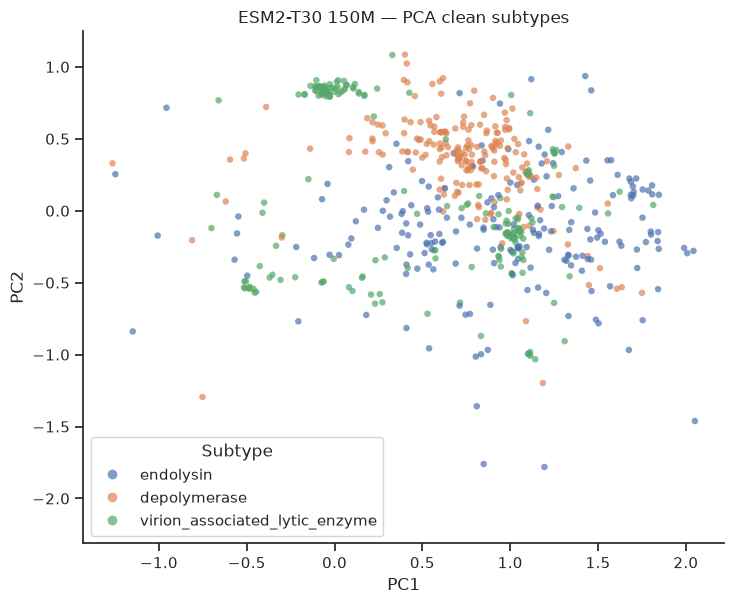

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_UMAP_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_UMAP_global.pdf


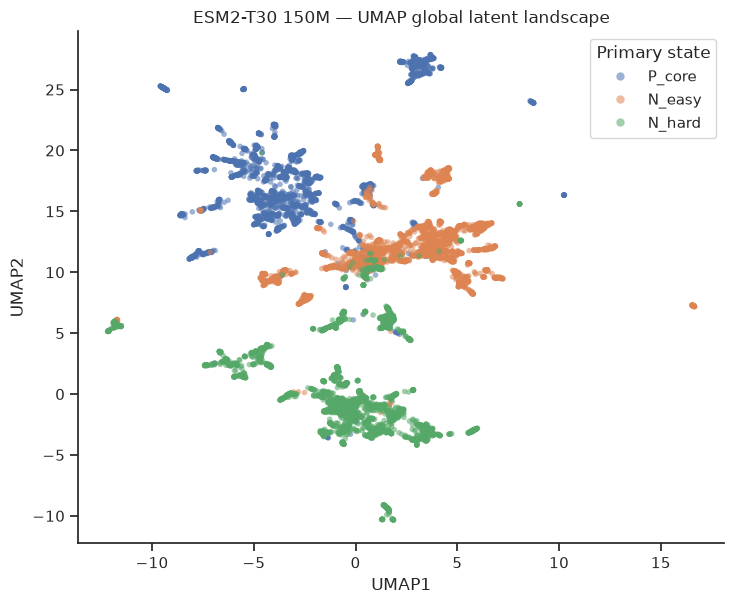

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_UMAP_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_UMAP_subtypes.pdf


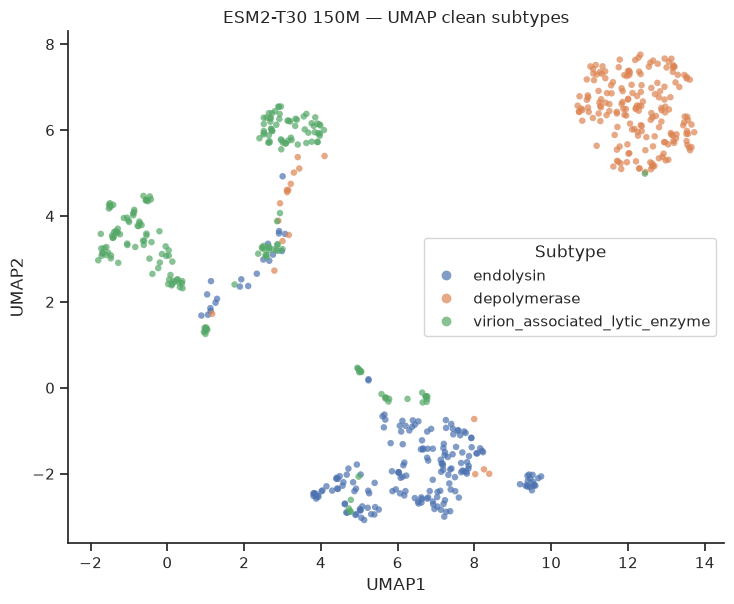

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_TSNE_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_TSNE_global.pdf


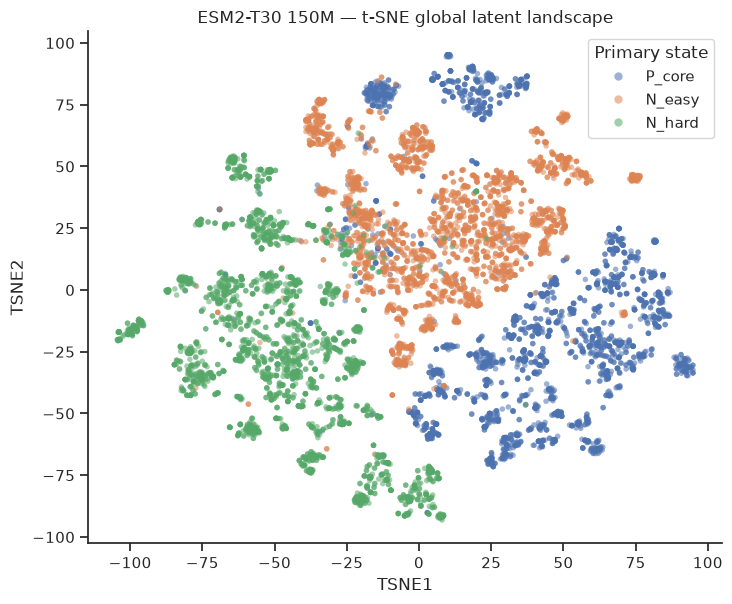

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_TSNE_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_esm2_t30_TSNE_subtypes.pdf


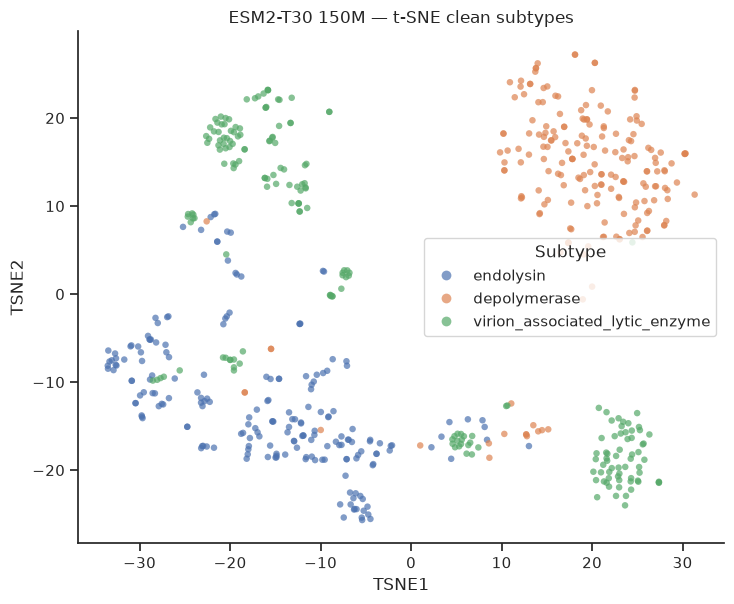

In [15]:
for rep, cfg in REPRESENTATIONS.items():
    pca_table = REP_DATA[rep]["pca_coordinates"]

    # PCA global
    plot_df = pca_table.loc[
        pca_table["in_global_viz_sample"]
        & pca_table["sequence_state"].isin(GLOBAL_HUE_ORDER)
    ]

    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    sns.scatterplot(
        data=plot_df,
        x="PC1",
        y="PC2",
        hue="sequence_state",
        hue_order=GLOBAL_HUE_ORDER,
        s=16,
        alpha=0.55,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{cfg['display_name']} — PCA global latent landscape")
    ax.legend(title="Primary state", markerscale=1.5)
    sns.despine()
    fig.tight_layout()
    save_figure(fig, f"E5_v2_{rep}_PCA_global")
    plt.show()

    # PCA subtypes
    plot_df = pca_table.loc[
        pca_table["in_subtype_viz_sample"]
        & pca_table["subtype_label"].isin(SUBTYPE_HUE_ORDER)
    ]

    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    sns.scatterplot(
        data=plot_df,
        x="PC1",
        y="PC2",
        hue="subtype_label",
        hue_order=SUBTYPE_HUE_ORDER,
        s=22,
        alpha=0.70,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{cfg['display_name']} — PCA clean subtypes")
    ax.legend(title="Subtype", markerscale=1.5)
    sns.despine()
    fig.tight_layout()
    save_figure(fig, f"E5_v2_{rep}_PCA_subtypes")
    plt.show()

    # UMAP global
    plot_df = REP_DATA[rep]["umap_global"]
    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    sns.scatterplot(
        data=plot_df,
        x="UMAP1",
        y="UMAP2",
        hue="sequence_state",
        hue_order=GLOBAL_HUE_ORDER,
        s=16,
        alpha=0.55,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{cfg['display_name']} — UMAP global latent landscape")
    ax.legend(title="Primary state", markerscale=1.5)
    sns.despine()
    fig.tight_layout()
    save_figure(fig, f"E5_v2_{rep}_UMAP_global")
    plt.show()

    # UMAP subtypes
    plot_df = REP_DATA[rep]["umap_subtypes"]
    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    sns.scatterplot(
        data=plot_df,
        x="UMAP1",
        y="UMAP2",
        hue="subtype_label",
        hue_order=SUBTYPE_HUE_ORDER,
        s=22,
        alpha=0.70,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{cfg['display_name']} — UMAP clean subtypes")
    ax.legend(title="Subtype", markerscale=1.5)
    sns.despine()
    fig.tight_layout()
    save_figure(fig, f"E5_v2_{rep}_UMAP_subtypes")
    plt.show()

    # t-SNE global
    plot_df = REP_DATA[rep]["tsne_global"]
    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    sns.scatterplot(
        data=plot_df,
        x="TSNE1",
        y="TSNE2",
        hue="sequence_state",
        hue_order=GLOBAL_HUE_ORDER,
        s=16,
        alpha=0.55,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{cfg['display_name']} — t-SNE global latent landscape")
    ax.legend(title="Primary state", markerscale=1.5)
    sns.despine()
    fig.tight_layout()
    save_figure(fig, f"E5_v2_{rep}_TSNE_global")
    plt.show()

    # t-SNE subtypes
    plot_df = REP_DATA[rep]["tsne_subtypes"]
    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    sns.scatterplot(
        data=plot_df,
        x="TSNE1",
        y="TSNE2",
        hue="subtype_label",
        hue_order=SUBTYPE_HUE_ORDER,
        s=22,
        alpha=0.70,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{cfg['display_name']} — t-SNE clean subtypes")
    ax.legend(title="Subtype", markerscale=1.5)
    sns.despine()
    fig.tight_layout()
    save_figure(fig, f"E5_v2_{rep}_TSNE_subtypes")
    plt.show()

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_cross_silhouette_global_three_state.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_cross_silhouette_global_three_state.pdf


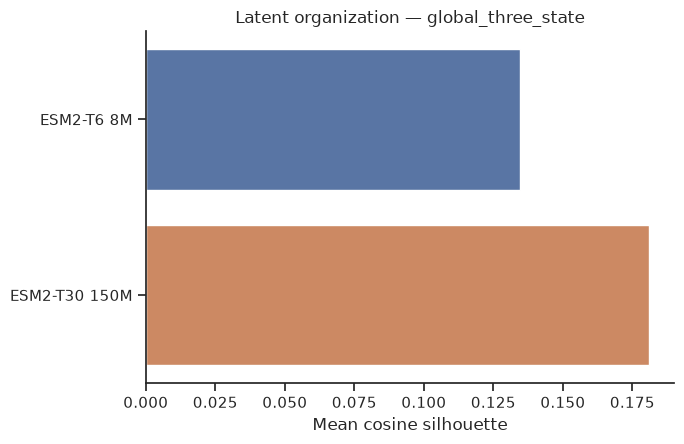

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_cross_knn25_global_three_state.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_cross_knn25_global_three_state.pdf


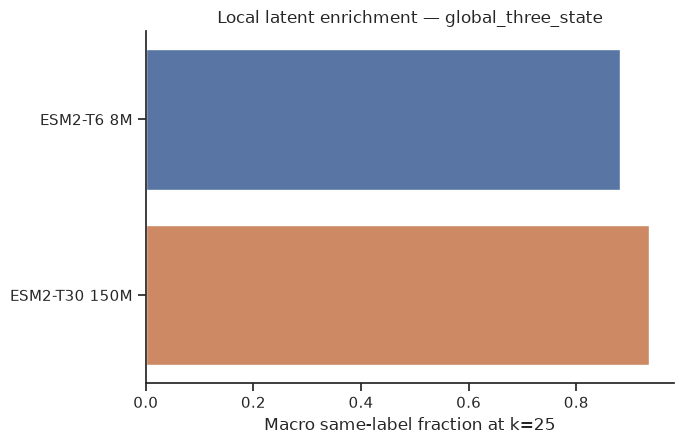

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_cross_silhouette_clean_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_cross_silhouette_clean_subtypes.pdf


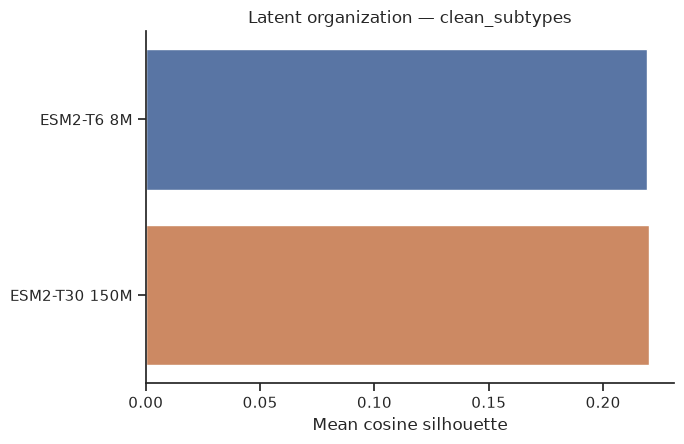

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_cross_knn25_clean_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2/figures/E5_v2_cross_knn25_clean_subtypes.pdf


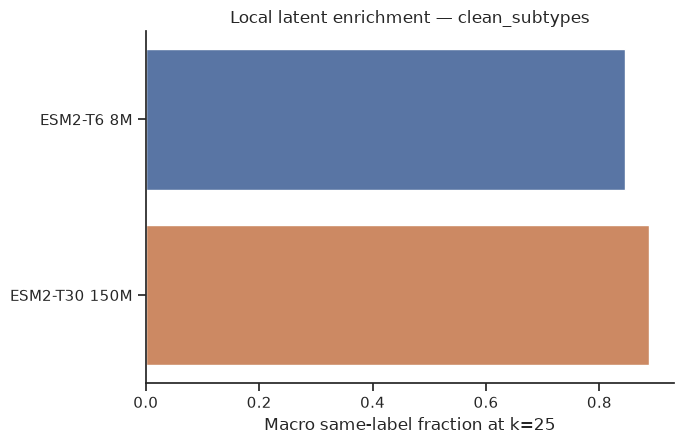

In [16]:
# Compare biological conclusions across embeddings, not geometric equivalence.
for scope_name in [
    "global_three_state",
    "clean_subtypes",
]:
    plot_df = cross_biological.loc[
        cross_biological["scope"].eq(scope_name)
        & cross_biological["metric"].eq("silhouette_cosine")
    ].copy()

    fig, ax = plt.subplots(figsize=(7.0, 4.6))
    sns.barplot(
        data=plot_df,
        y="display_name",
        x="mean",
        hue="display_name",
        dodge=False,
        legend=False,
        ax=ax,
    )
    ax.set_xlabel("Mean cosine silhouette")
    ax.set_ylabel("")
    ax.set_title(f"Latent organization — {scope_name}")
    sns.despine()
    fig.tight_layout()
    save_figure(fig, f"E5_v2_cross_silhouette_{scope_name}")
    plt.show()

    plot_df = cross_biological.loc[
        cross_biological["scope"].eq(scope_name)
        & cross_biological["metric"].eq("macro_same_label_knn_fraction")
        & cross_biological["k"].eq(25)
    ].copy()

    fig, ax = plt.subplots(figsize=(7.0, 4.6))
    sns.barplot(
        data=plot_df,
        y="display_name",
        x="mean",
        hue="display_name",
        dodge=False,
        legend=False,
        ax=ax,
    )
    ax.set_xlabel("Macro same-label fraction at k=25")
    ax.set_ylabel("")
    ax.set_title(f"Local latent enrichment — {scope_name}")
    sns.despine()
    fig.tight_layout()
    save_figure(fig, f"E5_v2_cross_knn25_{scope_name}")
    plt.show()

## 13. Final closure audit

In [17]:
assert EMBEDDING_GENERATION_DISABLED is True
assert set(REPRESENTATIONS) == {"esm2_t6", "esm2_t30"}

assert len(e0) == 442_329
assert len(common_labels) == 434_768
assert exact_uid_contract

assert REPRESENTATIONS["esm2_t6"]["expected_dimensions"] == 320
assert REPRESENTATIONS["esm2_t30"]["expected_dimensions"] == 640

assert not embedding_availability.empty
assert not pca_variance.empty
assert not cross_biological.empty
assert not cross_neighborhood.empty

for rep in REPRESENTATIONS:
    cfg = REPRESENTATIONS[rep]

    assert len(cfg["feature_columns"]) == cfg["expected_dimensions"]
    assert not REP_DATA[rep]["geometry_summary"].empty
    assert not REP_DATA[rep]["neighbor_summary"].empty

    required_rep_outputs = [
        RESULT_DIR / f"embedding_{rep}_pca.tsv",
        RESULT_DIR / f"embedding_{rep}_umap_global.tsv",
        RESULT_DIR / f"embedding_{rep}_umap_subtypes.tsv",
        RESULT_DIR / f"embedding_{rep}_tsne_global.tsv",
        RESULT_DIR / f"embedding_{rep}_tsne_subtypes.tsv",
        RESULT_DIR / f"embedding_{rep}_geometry.tsv",
        RESULT_DIR / f"embedding_{rep}_neighbors.tsv",
        RESULT_DIR / f"embedding_{rep}_geometry_repeats.tsv",
        RESULT_DIR / f"embedding_{rep}_neighbor_repeats.tsv",
    ]

    for path in required_rep_outputs:
        assert path.is_file(), f"Missing E5_v2 output: {path}"

assert set(cross_biological["representation"]) == set(REPRESENTATIONS)
assert set(cross_neighborhood["representation"]) == set(REPRESENTATIONS)

required_outputs = [
    AVAILABILITY_PATH,
    COMMON_UNIVERSE_PATH,
    SAMPLE_MANIFEST_PATH,
    PCA_VARIANCE_PATH,
    CROSS_BIOLOGICAL_PATH,
    CROSS_NEIGHBORHOOD_PATH,
]

for path in required_outputs:
    assert path.is_file(), f"Missing E5_v2 output: {path}"

neighbor_sum_audit = (
    cross_neighborhood
    .groupby(
        [
            "representation",
            "scope",
            "k",
            "focal_group",
        ],
        dropna=False,
    )["mean_neighbor_fraction"]
    .sum()
)

if not np.allclose(
    neighbor_sum_audit.to_numpy(),
    1.0,
    atol=1e-6,
):
    raise RuntimeError(
        "Neighborhood composition does not sum to 1."
    )

metadata = {
    "stage": "E5_v2",
    "scientific_question": (
        "How is the phage-lytic protein space organized "
        "in learned PLM latent representations?"
    ),
    "embedding_generation_disabled": True,
    "representations": {
        rep: {
            "display_name": cfg["display_name"],
            "model": cfg["model"],
            "dimensions": cfg["expected_dimensions"],
            "row_count": cfg["row_count"],
            "pool": cfg["metadata_payload"].get("pool"),
            "layers": cfg["metadata_payload"].get("layers"),
            "precision": cfg["metadata_payload"].get("precision"),
            "max_length": cfg["metadata_payload"].get("max_length"),
        }
        for rep, cfg in REPRESENTATIONS.items()
    },
    "frozen_e0_rows": int(len(e0)),
    "common_embedding_rows": int(len(common_labels)),
    "not_embedded_rows": int(len(e0) - len(common_labels)),
    "quantitative_distance_metric": "cosine",
    "pca_components": PCA_COMPONENTS,
    "umap": {
        "metric": "cosine",
        "n_neighbors": UMAP_N_NEIGHBORS,
        "min_dist": UMAP_MIN_DIST,
        "fit_separately_by_biological_scope": True,
    },
    "tsne": {
        "visualization_only": True,
        "pre_pca_components": TSNE_PRE_PCA_COMPONENTS,
        "perplexity": TSNE_PERPLEXITY,
        "max_iter": TSNE_MAX_ITER,
        "fit_separately_by_biological_scope": True,
    },
    "neighbor_k_values": NEIGHBOR_K_VALUES,
    "global_metric_repeats": GLOBAL_METRIC_REPEATS,
    "subtype_metric_repeats": SUBTYPE_METRIC_REPEATS,
    "cross_embedding_geometric_equivalence_tested": False,
    "random_seed": RANDOM_SEED,
}

METADATA_PATH.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("=" * 72)
print("PASS — E5_v2 latent landscape completed.")
print("=" * 72)
print()
print("No embeddings were generated.")
print("T6 and T30 were analyzed independently as biological latent spaces.")
print("UMAP and t-SNE were fitted separately for global states and clean subtypes.")
print("No T6↔T30 geometric-equivalence metrics were calculated.")
print()
print(f"Results: {RESULT_DIR}")

PASS — E5_v2 latent landscape completed.

No embeddings were generated.
T6 and T30 were analyzed independently as biological latent spaces.
UMAP and t-SNE were fitted separately for global states and clean subtypes.
No T6↔T30 geometric-equivalence metrics were calculated.

Results: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5_v2
